In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/milan.csv")
df.head()

,time,temperature_2m_mean,temperature_2m_max,precipitation_sum,city
0,1950-01-01,0.9,3.6,0.0,Milan
1,1950-01-02,-1.6,3.4,0.0,Milan
2,1950-01-03,1.3,8.5,0.0,Milan
3,1950-01-04,1.4,7.4,0.0,Milan
4,1950-01-05,1.4,8.4,0.0,Milan


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27759 entries, 0 to 27758
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   time                 27759 non-null  str    
 1   temperature_2m_mean  27759 non-null  float64
 2   temperature_2m_max   27759 non-null  float64
 3   precipitation_sum    27759 non-null  float64
 4   city                 27759 non-null  str    
dtypes: float64(3), str(2)
memory usage: 1.5 MB


In [4]:
df.isna().sum()

time                   0
temperature_2m_mean    0
temperature_2m_max     0
precipitation_sum      0
city                   0
dtype: int64

No missing values in any column. 27759 rows, one for each day from 1950 to 2025.


In [5]:
df.describe()

,temperature_2m_mean,temperature_2m_max,precipitation_sum
count,27759.000000,27759.000000,27759.000000
mean,12.217076,16.797655,3.237642
std,7.991440,8.324841,7.602887
min,-13.600000,-7.400000,0.000000
25%,5.400000,9.800000,0.000000
50%,12.400000,16.900000,0.000000
75%,18.900000,23.600000,2.200000
max,31.800000,38.400000,96.900000


The average day in Milan is about 12 °C. The coldest day was -13.6 °C and the hottest max temperature was 38.4 °C. For rain, the median is 0, so on most days it does not rain, but one day had almost 97 mm. Because rain is 0 on most days, it makes more sense to add it up per year than to take the average.

In [6]:
df["time"] = pd.to_datetime(df["time"])
df["time"].min(), df["time"].max()

(Timestamp('1950-01-01 00:00:00'), Timestamp('2025-12-31 00:00:00'))

The time column was text, so I changed it to dates. The data goes from 1 January 1950 to 31 December 2025, so nothing is missing at the start or end.

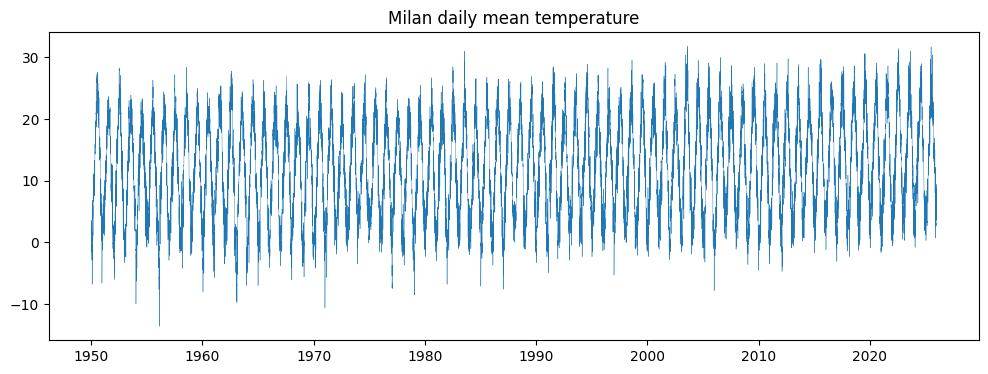

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(df["time"], df["temperature_2m_mean"], linewidth=0.3)
plt.title("Milan daily mean temperature")
plt.show()

<Axes: title={'center': 'Milan yearly average'}, xlabel='year'>

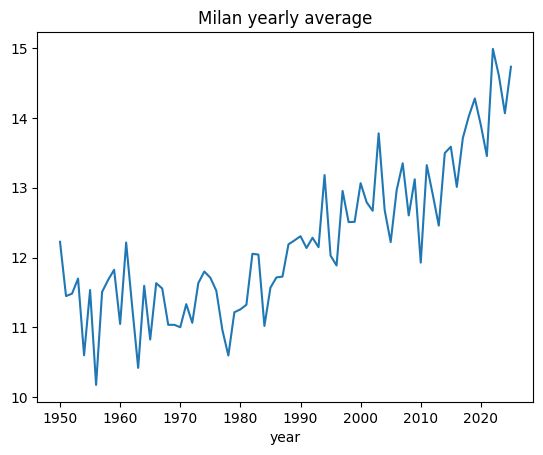

In [8]:
df["year"] = df["time"].dt.year
yearly = df.groupby("year")["temperature_2m_mean"].mean()
yearly.plot(title="Milan yearly average")

The daily plot is too noisy, I can only see summer and winter. The yearly average is much clearer: it stays around 11 to 12 °C until about 1980, then it goes up to around 14 to 15 °C in the last years. So in the project I will work with yearly values.

In [9]:
for t in [25, 30, 35]:
    print(t, (df["temperature_2m_max"] >= t).sum())

25 5465
30 1327
35 77


25 is too common (around 72 days a year, normal summer). 35 is too rare (around 1 a year). 30 gives around 17 a year, so I use 30 as a hot day.

<Axes: title={'center': 'Days over 30 in Milan'}, xlabel='year'>

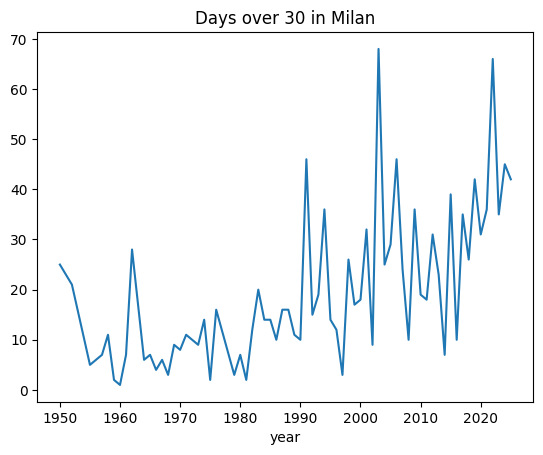

In [10]:
hot = df[df["temperature_2m_max"] >= 30].groupby("year").size()
hot.plot(title="Days over 30 in Milan")

Hot days went from about 5 to 15 per year before 1990 to around 30 to 45 per year now. The highest years are 2003 and 2022, both very hot summers in Europe.

I noticed a problem: years with zero hot days are missing in this plot, because groupby().size() only counts years that have at least one hot day. So the line jumps over them. In the project I fixed this by counting True/False values with sum(), so years with 0 hot days are included.

In [11]:
for city in ["rome", "riga", "delhi"]:
    d = pd.read_csv(f"../data/{city}.csv")
    print(city, len(d), d.isna().sum().sum())

rome 27759 0
riga 27759 0
delhi 27759 0


Rome, Riga and Delhi also have 27759 rows and no missing values, so all four cities are complete and I can compare them.

What I decided for the project
Use yearly averages instead of daily values, because daily data is too noisy.
A hot day is a day with max temperature of 30 °C or more.
Count hot days with True/False and sum, so years with 0 hot days are not lost.
Add up rain per year instead of taking the average.
All cities are complete, so no big cleaning is needed. I still keep dropna() in the code to be safe.